# Sentiment &amp; Fake News Detection Pipeline

# Phase 1

- ### The goal of this project is to analyze and classify text data using machine learning techniques.  


## Import Libraries

### Make sure the following libraries are installed

In [ ]:
!pip install nltk wordcloud

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
from collections import Counter

# NLP stopwords
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


## Load Dataset

### Twitter Sentiment 140 dataset
https://www.kaggle.com/datasets/kazanova/sentiment140


In [ ]:
import kagglehub
import pandas as pd
import os

# Download latest version
path = kagglehub.dataset_download("kazanova/sentiment140")

# Construct the full path to the CSV file within the downloaded directory
csv_file_path = os.path.join(path, 'training.1600000.processed.noemoticon.csv')

print("Path to dataset files:", csv_file_path)
df = pd.read_csv(csv_file_path ,
         encoding='latin-1',
               names=["sentiment","id","date","flag","user","text"])

df = df[['sentiment','text']]
df.head()

Using Colab cache for faster access to the 'sentiment140' dataset.
Path to dataset files: /kaggle/input/sentiment140/training.1600000.processed.noemoticon.csv


,sentiment,text
0,0,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,is upset that he can't update his Facebook by ...
2,0,@Kenichan I dived many times for the ball. Man...
3,0,my whole body feels itchy and like its on fire
4,0,"@nationwideclass no, it's not behaving at all...."


## Text Preprocessing for Classical ML

The dataset labels are:

- 0 = negative
- 4 = positive

Convert them to 0 and 1

In [ ]:
df['sentiment'] = df['sentiment'].replace(4, 1)

df['sentiment'].value_counts()

def clean_text(text):
    text = text.lower()                          # lowercase
    text = re.sub(r"http\S+", "", text)          # remove URLs
    text = re.sub(r"[^a-zA-Z ]", "", text)      # remove punctuation & numbers
    words = text.split()
    words = [w for w in words if w not in stop_words]
    return " ".join(words)

df['clean_text'] = df['text'].apply(clean_text)
df.head()

,sentiment,text,clean_text
0,0,"@switchfoot http://twitpic.com/2y1zl - Awww, t...",switchfoot awww thats bummer shoulda got david...
1,0,is upset that he can't update his Facebook by ...,upset cant update facebook texting might cry r...
2,0,@Kenichan I dived many times for the ball. Man...,kenichan dived many times ball managed save re...
3,0,my whole body feels itchy and like its on fire,whole body feels itchy like fire
4,0,"@nationwideclass no, it's not behaving at all....",nationwideclass behaving im mad cant see


## EDA (Exploratory Data Analysis)

### Data Info

In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1600000 entries, 0 to 1599999
Data columns (total 3 columns):
 #   Column      Non-Null Count    Dtype 
---  ------      --------------    ----- 
 0   sentiment   1600000 non-null  int64 
 1   text        1600000 non-null  object
 2   clean_text  1600000 non-null  object
dtypes: int64(1), object(2)
memory usage: 36.6+ MB


,sentiment
count,1600000.0
mean,0.5
std,0.5
min,0.0
25%,0.0
50%,0.5
75%,1.0
max,1.0


### Class Distribution

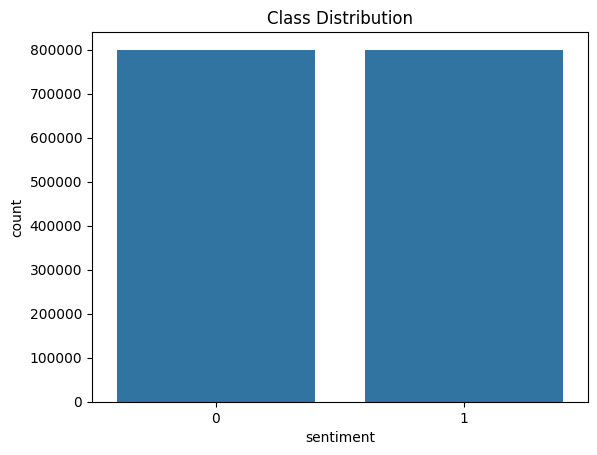

In [ ]:
sns.countplot(x='sentiment', data=df)
plt.title("Class Distribution")
plt.show()

### Tweet Length Analysis

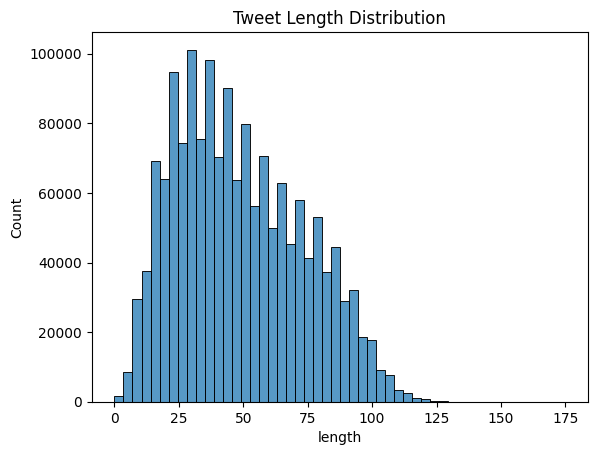

In [ ]:
df['length'] = df['clean_text'].apply(len)

sns.histplot(df['length'], bins=50)
plt.title("Tweet Length Distribution")
plt.show()

### Most Frequent Words

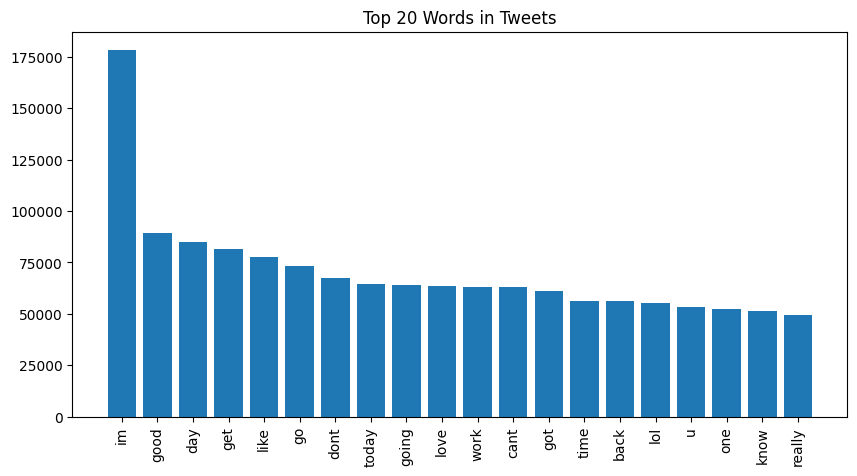

In [ ]:
all_words = " ".join(df['clean_text']).split()
common_words = Counter(all_words).most_common(20)

words = [i[0] for i in common_words]
counts = [i[1] for i in common_words]

plt.figure(figsize=(10,5))
plt.bar(words, counts)
plt.xticks(rotation=90)
plt.title("Top 20 Words in Tweets")
plt.show()

### Word Cloud

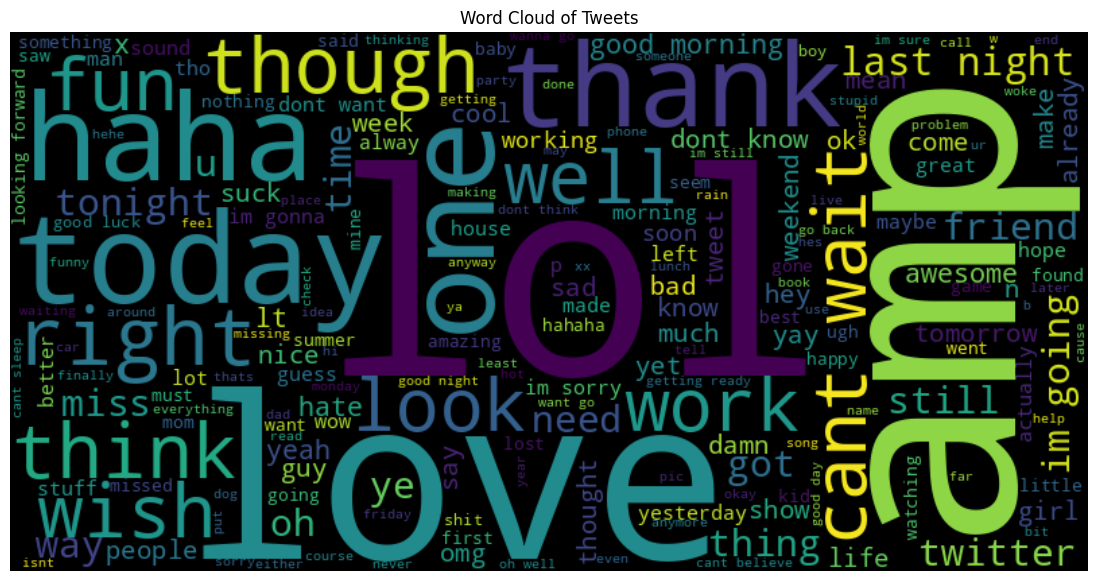

In [ ]:
from wordcloud import WordCloud

text = " ".join(df['clean_text'])
wordcloud = WordCloud(width=800, height=400).generate(text)

plt.figure(figsize=(15,7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Tweets")
plt.show()

## Sampling the Dataset for Testing

We will take a smaller sample of 50,000 tweets from the full dataset of 1.6 milion tweets.
This will reduce computation time when testing TF-IDF and KNN,
while still providing a representative subset of the data.

In [ ]:
#use sample from dataset for testing  TF-IDF , KNN
df = df.sample(50000, random_state=42)

## TF-IDF feature extraction for the Sentiment dataset

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

texts = df["clean_text"]
labels = df["sentiment"]

vectorizer = TfidfVectorizer(max_features=5000)#top 5000 words

x=vectorizer.fit_transform(texts)
y=labels

print("TF-IDF matrix shape:", x.shape) # 50000 tweets & 5000 word features

TF-IDF matrix shape: (50000, 5000)


## Dimensonality reduction

### LSA (Latent Semantic Analysis) using Truncated SVD

In [ ]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=200, random_state=42) # reduce from 5000 features to 200 features
x_reduced = svd.fit_transform(x)

print("Reduced shape:", x_reduced.shape)
print("Explained variance:", svd.explained_variance_ratio_.sum())

Reduced shape: (50000, 200)
Explained variance: 0.33619344713473454


### LSA 2D visualization


In [ ]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=2, random_state=42)
X_reduced = svd.fit_transform(x)

print("Original shape:", x.shape)
print("Reduced shape:", X_reduced.shape)

Original shape: (50000, 5000)
Reduced shape: (50000, 2)


### 2D Visualization

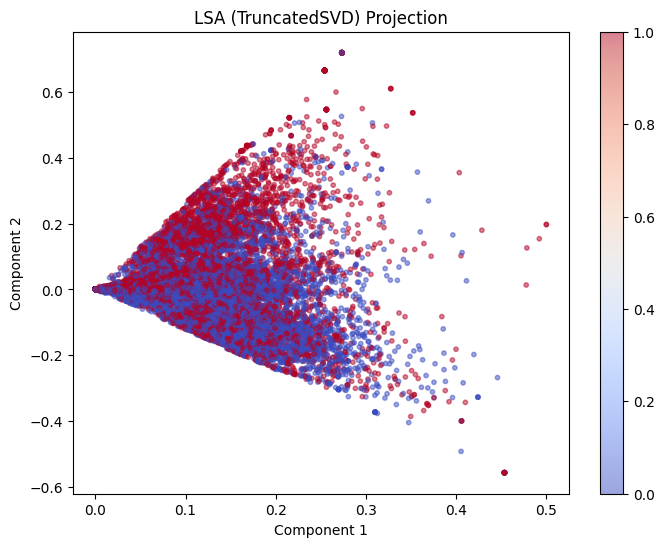

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_reduced[:,0],
    X_reduced[:,1],
    c=y,
    cmap='coolwarm',
    alpha=0.5,
    s=10
)

plt.title("LSA (TruncatedSVD) Projection")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.colorbar()
plt.show()

### Explained Variance Plot

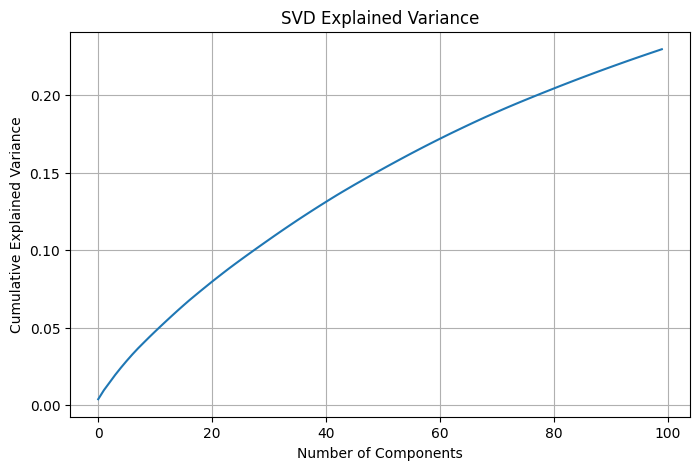

In [ ]:
from sklearn.decomposition import TruncatedSVD
import numpy as np
import matplotlib.pyplot as plt

svd_full = TruncatedSVD(n_components=100, random_state=42)
svd_full.fit(x)

explained_variance = np.cumsum(svd_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(explained_variance)
plt.title("SVD Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.grid()
plt.show()

## Models

### K-Nearest Neighbors (KNN)
If most nearby tweets are:
- positive → classify positive
- negative → classify negative

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score, roc_auc_score

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y #keeps class balance
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

knn_results = {}

for k in [3, 5, 7]:
    knn_model = KNeighborsClassifier(n_neighbors=k)
    knn_model.fit(x_train, y_train)

    knn_preds = knn_model.predict(x_test)
    knn_probs = knn_model.predict_proba(x_test)[:, 1]

    acc = accuracy_score(y_test, knn_preds)
    """
    acc= TP+TN/TP+TN+FP+FN
    """
    f1 = f1_score(y_test, knn_preds)
    """
    f1= 2*precision*recall/(precision+recall)
    """
    auc_score = roc_auc_score(y_test, knn_probs)
    """
    auc= TP/(TP+FN)
    """

    knn_results[k] = {"accuracy": acc, "f1": f1, "auc": auc_score}

    print(f"\nKNN (k={k})")
    print("Accuracy:", acc)
    print("F1-score:", f1)
    print("AUC:", auc_score)

best_k = max(knn_results, key=lambda k: knn_results[k]["accuracy"])
print("\nBest KNN:", best_k, knn_results[best_k])

Training data: (40000, 5000)
Testing data: (10000, 5000)

KNN (k=3)
Accuracy: 0.5885
F1-score: 0.6153846153846154
AUC: 0.6228398642223512

KNN (k=5)
Accuracy: 0.5794
F1-score: 0.613561190738699
AUC: 0.6244308647951113

KNN (k=7)
Accuracy: 0.5843
F1-score: 0.6280755122125794
AUC: 0.6270797657487157

Best KNN: 3 {'accuracy': 0.5885, 'f1': 0.6153846153846154, 'auc': np.float64(0.6228398642223512)}


### Naïve Bayes Classifier

In [ ]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB() #calculates probability of a class given words
nb_model.fit(x_train, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


### Predictions and Evaluation

In [ ]:
# Generate predictions
nb_predictions = nb_model.predict(x_test)

print("First few predictions:")
print(nb_predictions[:20])

First few predictions:
[0 0 0 0 1 0 0 0 0 0 1 0 0 1 1 1 0 1 0 1]


### Classification Report

In [ ]:
from sklearn.metrics import classification_report

print("Classification Report:\n")

print(classification_report(y_test, nb_predictions))

Classification Report:

              precision    recall  f1-score   support

           0       0.75      0.74      0.74      4997
           1       0.74      0.75      0.75      5003

    accuracy                           0.75     10000
   macro avg       0.75      0.75      0.75     10000
weighted avg       0.75      0.75      0.75     10000



### ROC Curve and AUC

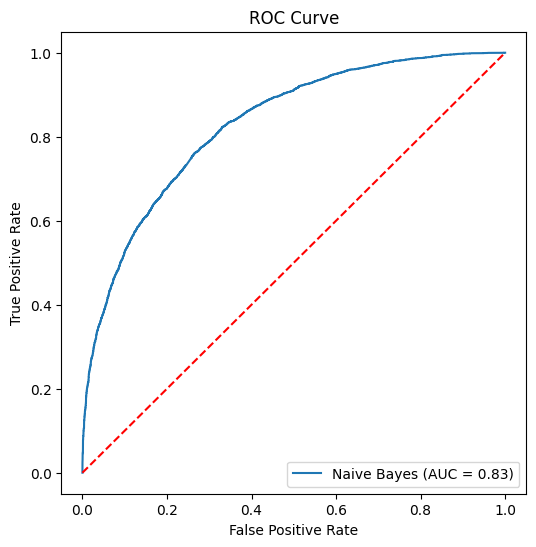

In [ ]:
from sklearn.metrics import roc_curve, auc

nb_prob = nb_model.predict_proba(x_test)[:,1]

# Calculate ROC
fpr, tpr, thresholds = roc_curve(y_test, nb_prob)

roc_auc = auc(fpr, tpr)

# Plot ROC
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label="Naive Bayes (AUC = %0.2f)" % roc_auc)

plt.plot([0,1],[0,1],'r--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend(loc="lower right")

plt.show()

In [ ]:
nb_accuracy = accuracy_score(y_test, nb_predictions)
nb_f1 = f1_score(y_test, nb_predictions)
nb_auc = roc_auc

### Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score

rf_model = RandomForestClassifier(
    n_estimators=100, # 100 decision trees working togther
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(x_train, y_train) #learns patterns from TF-IDF features

rf_preds = rf_model.predict(x_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_preds))
print("Random Forest F1-score:", f1_score(y_test, rf_preds))
print("\nClassification Report:\n", classification_report(y_test, rf_preds))

Random Forest Accuracy: 0.7049
Random Forest F1-score: 0.7332549941245593

Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.60      0.67      4997
           1       0.67      0.81      0.73      5003

    accuracy                           0.70     10000
   macro avg       0.71      0.70      0.70     10000
weighted avg       0.71      0.70      0.70     10000



In [ ]:
rf_accuracy = accuracy_score(y_test, rf_preds)
rf_f1 = f1_score(y_test, rf_preds)

### Random Forest Hyperparameter Tuning

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

best_score = 0
best_params = {}

for n in [50, 100, 200]:
    for depth in [10, 20, None]:

        rf = RandomForestClassifier(
            n_estimators=n,
            max_depth=depth,
            random_state=42,
            n_jobs=-1
        )

        rf.fit(x_train, y_train)
        preds = rf.predict(x_test)

        acc = accuracy_score(y_test, preds)

        print(f"n_estimators={n}, max_depth={depth} → Accuracy: {acc:.4f}")

        if acc > best_score:
            best_score = acc
            best_params = {"n_estimators": n, "max_depth": depth}

print("\nBest RF Params:", best_params)
print("Best RF Accuracy:", best_score)

n_estimators=50, max_depth=10 → Accuracy: 0.6879
n_estimators=50, max_depth=20 → Accuracy: 0.6997
n_estimators=50, max_depth=None → Accuracy: 0.7455
n_estimators=100, max_depth=10 → Accuracy: 0.6926
n_estimators=100, max_depth=20 → Accuracy: 0.7049
n_estimators=100, max_depth=None → Accuracy: 0.7483
n_estimators=200, max_depth=10 → Accuracy: 0.7020
n_estimators=200, max_depth=20 → Accuracy: 0.7091
n_estimators=200, max_depth=None → Accuracy: 0.7484

Best RF Params: {'n_estimators': 200, 'max_depth': None}
Best RF Accuracy: 0.7484


### XGBoost

In [ ]:
!pip install xgboost
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42
)

xgb_model.fit(x_train, y_train)

xgb_preds = xgb_model.predict(x_test)

print("XGBoost Accuracy:", accuracy_score(y_test, xgb_preds))
print("XGBoost F1-score:", f1_score(y_test, xgb_preds))

XGBoost Accuracy: 0.7197
XGBoost F1-score: 0.7482712168837


In [ ]:
xgb_accuracy = accuracy_score(y_test, xgb_preds)
xgb_f1 = f1_score(y_test, xgb_preds)

### XGBoost Hyperparameter Tuning

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

best_score = 0
best_params = {}

for depth in [4, 6, 8]:
    for lr in [0.05, 0.1, 0.2]:

        xgb = XGBClassifier(
            n_estimators=200,
            max_depth=depth,
            learning_rate=lr,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric='logloss',
            random_state=42
        )

        xgb.fit(x_train, y_train)
        preds = xgb.predict(x_test)

        acc = accuracy_score(y_test, preds)

        print(f"depth={depth}, lr={lr} → Accuracy: {acc:.4f}")

        if acc > best_score:
            best_score = acc
            best_params = {"max_depth": depth, "learning_rate": lr}

print("\nBest XGB Params:", best_params)
print("Best XGB Accuracy:", best_score)

depth=4, lr=0.05 → Accuracy: 0.6835
depth=4, lr=0.1 → Accuracy: 0.7070
depth=4, lr=0.2 → Accuracy: 0.7306
depth=6, lr=0.05 → Accuracy: 0.6979
depth=6, lr=0.1 → Accuracy: 0.7197
depth=6, lr=0.2 → Accuracy: 0.7403
depth=8, lr=0.05 → Accuracy: 0.7083
depth=8, lr=0.1 → Accuracy: 0.7297
depth=8, lr=0.2 → Accuracy: 0.7433

Best XGB Params: {'max_depth': 8, 'learning_rate': 0.2}
Best XGB Accuracy: 0.7433


### Random Forest VS XGBoost


In [ ]:
print("RF vs XGB Comparison:")
print("Random Forest:", accuracy_score(y_test, rf_preds))
print("XGBoost:", accuracy_score(y_test, xgb_preds))

RF vs XGB Comparison:
Random Forest: 0.7049
XGBoost: 0.7197


# Phase 2

## Text Preprocessing for Deep Learning


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer # to convert words into numbers
from tensorflow.keras.preprocessing.sequence import pad_sequences #to make all sequences the same length

texts = df["clean_text"].values
labels = df["sentiment"].values

### Tokenization

In [ ]:
tokenizer = Tokenizer(num_words=10000) #10,000 most frequent words.
tokenizer.fit_on_texts(texts)

sequences = tokenizer.texts_to_sequences(texts)

### Padding Sequences

In [ ]:
max_len = 100

X = pad_sequences(sequences, maxlen=max_len, padding='post')
y = labels

### Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Load Embeddings

In [ ]:
import os
import numpy as np

# Download only if needed
if not os.path.exists("glove.6B.100d.txt"):
    !wget http://nlp.stanford.edu/data/glove.6B.zip
    !unzip glove.6B.zip

embedding_index = {}

with open("glove.6B.100d.txt", encoding="utf8") as f:
    for line in f:
        values = line.split()
        word = values[0]
        coeffs = np.asarray(values[1:], dtype='float32')
        embedding_index[word] = coeffs

print("Loaded embeddings:", len(embedding_index))

--2026-05-15 04:52:16--  http://nlp.stanford.edu/data/glove.6B.zip
Resolving nlp.stanford.edu (nlp.stanford.edu)... 171.64.67.140
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://nlp.stanford.edu/data/glove.6B.zip [following]
--2026-05-15 04:52:17--  https://nlp.stanford.edu/data/glove.6B.zip
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip [following]
--2026-05-15 04:52:17--  https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip
Resolving downloads.cs.stanford.edu (downloads.cs.stanford.edu)... 171.64.64.22
Connecting to downloads.cs.stanford.edu (downloads.cs.stanford.edu)|171.64.64.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 862182613 (822M) [application/zip]
Saving to: ‘glove.6B.zip’

glov

## Build Embedding Matrix

In [ ]:
embedding_dim = 100
word_index = tokenizer.word_index

num_words = 10000
embedding_matrix = np.zeros((num_words, embedding_dim))

for word, i in word_index.items():
    if i < num_words:
        vec = embedding_index.get(word)
        if vec is not None:
            embedding_matrix[i] = vec

## CNN Model Architecture

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, MaxPooling1D
from tensorflow.keras.layers import GlobalMaxPooling1D, Dense, Dropout
from tensorflow.keras import Input

def do_model(optimizerName):
    model = Sequential()

    # Input + Embedding
    model.add(Input(shape=(100,)))
    model.add(
      Embedding(
          input_dim=10000,
          output_dim=100,
          weights=[embedding_matrix],
          input_length=100,
          trainable=False
      )
    )

    # Conv Layer 1
    model.add(Conv1D(filters=128, kernel_size=5, activation='relu'))
    model.add(MaxPooling1D(pool_size=2))

    # Conv Layer 2
    model.add(Conv1D(filters=64, kernel_size=3, activation='relu'))

    # Global Pooling
    model.add(GlobalMaxPooling1D())

    # Dense Layer
    model.add(Dense(64, activation='relu'))

    # Dropout
    model.add(Dropout(0.5))

    # Output
    model.add(Dense(1, activation='sigmoid'))

    model.compile(
        optimizer=optimizerName,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

### Model Checkpoint

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint = ModelCheckpoint(
    "cnn_best_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

### Model Training

In [ ]:
model = do_model("adam")

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=5,
    batch_size=128,
    callbacks=[checkpoint]
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6222 - loss: 0.6400
Epoch 1: val_accuracy improved from None to 0.70140, saving model to cnn_best_model.keras

Epoch 1: finished saving model to cnn_best_model.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.6676 - loss: 0.6071 - val_accuracy: 0.7014 - val_loss: 0.5664
Epoch 2/5
302/313 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7274 - loss: 0.5436
Epoch 2: val_accuracy improved from 0.70140 to 0.71980, saving model to cnn_best_model.keras

Epoch 2: finished saving model to cnn_best_model.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7295 - loss: 0.5392 - val_accuracy: 0.7198 - val_loss: 0.5425
Epoch 3/5
309/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7579 - loss: 0.4965
Epoch 3: val_accuracy improved from 0.71980 to 0.72570, saving model to cnn_best_model.keras

Epoch 3: finished saving model to cnn_best_model.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7580 - lo

### Training Curves

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("cnn_best_model.keras")

#### Accuracy Curve


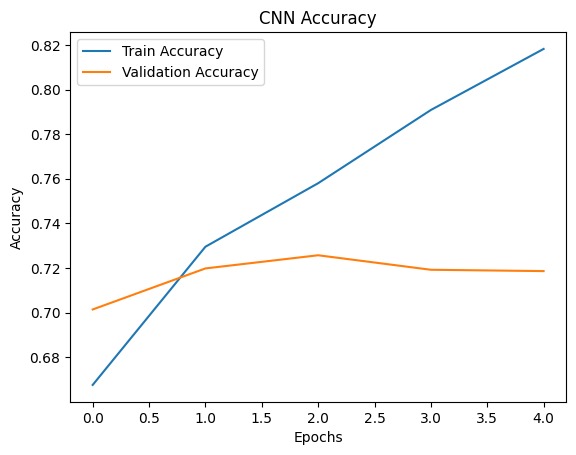

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("CNN Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

#### Loss Curve

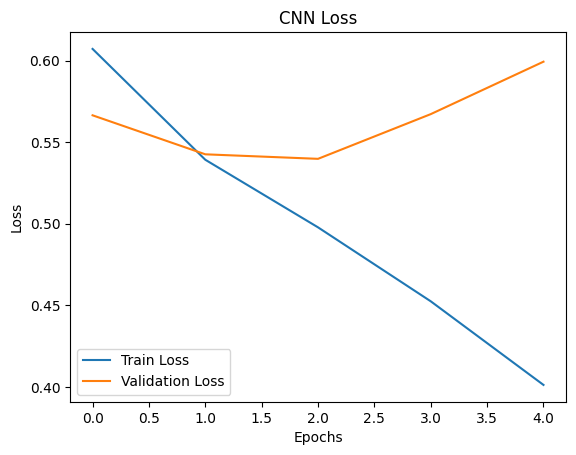

In [ ]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("CNN Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Predictions and Evaluation

In [ ]:
predictions = model.predict(x_test)
predictions = (predictions > 0.5).astype(int)

print("Sample predictions:")
print(predictions[:20])

cnn_loss, cnn_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", cnn_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Sample predictions:
[[0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]]
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7257 - loss: 0.5398
Test Accuracy: 0.7257000207901001


## Confusion Matrix

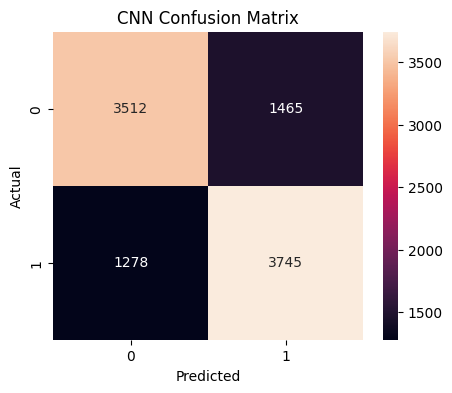

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d')
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## ROC Curve

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


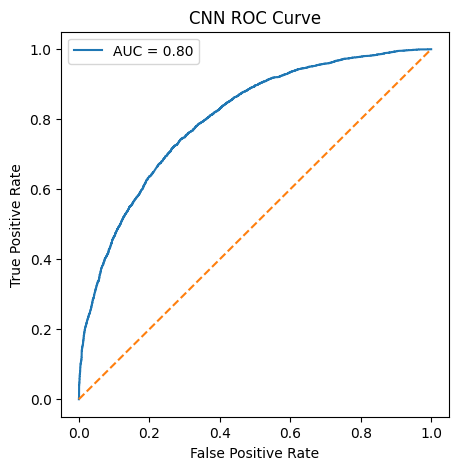

In [ ]:
from sklearn.metrics import roc_curve, auc

y_prob = model.predict(x_test).ravel()

cnn_auc = roc_auc

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(5,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CNN ROC Curve")
plt.legend()
plt.show()

## CNN summary

In [ ]:
loss, accuracy = model.evaluate(x_test, y_test)
print("CNN FINAL RESULTS")
print("-----------------")
print("Accuracy:", accuracy)
print("Loss:", loss)
print("AUC:", roc_auc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7257 - loss: 0.5398
CNN FINAL RESULTS
-----------------
Accuracy: 0.7257000207901001
Loss: 0.5397731065750122
AUC: 0.8032354164614124


###Optimizer & Hyperparameter Comparison

In this section, we compare different optimizers (Adam, SGD, RMSprop) on the same CNN model to evaluate their performance on text classification.

In [ ]:
from tensorflow.keras.optimizers import Adam, SGD, RMSprop

optimizers = {
    "Adam": Adam(learning_rate=0.001),
    "SGD": SGD(learning_rate=0.01),
    "RMSprop": RMSprop(learning_rate=0.001)
}

###Train models

In [ ]:
histories = {}
optimizer_results = {}

for name, opt in optimizers.items():
    print(f"\nTraining with {name}...\n")

    model = do_model(opt)

    history = model.fit(
        x_train,
        y_train,
        validation_data=(x_test, y_test),
        epochs=5,
        batch_size=128,
        verbose=1
    )

    histories[name] = history

    loss, acc = model.evaluate(x_test, y_test, verbose=0)
    optimizer_results[name] = {"loss": loss, "accuracy": acc}

    print("\nFinal Results:\n")

for name, vals in optimizer_results.items():
    print(f"{name}: Accuracy = {vals['accuracy']:.4f}, Loss = {vals['loss']:.4f}")


Training with Adam...

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.6716 - loss: 0.6035 - val_accuracy: 0.7131 - val_loss: 0.5596
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.7288 - loss: 0.5391 - val_accuracy: 0.7216 - val_loss: 0.5438
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7558 - loss: 0.5002 - val_accuracy: 0.7267 - val_loss: 0.5379
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7853 - loss: 0.4557 - val_accuracy: 0.7132 - val_loss: 0.5619
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8182 - loss: 0.4026 - val_accuracy: 0.7182 - val_loss: 0.5762

Final Results:


Training with SGD...

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.5255 - loss: 0.6931 - val_accuracy: 0.5579 - val_loss: 0.6853
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5630 - loss: 0.6824 - val_accuracy: 0.5953 - val_loss: 0.6743
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5983 - loss: 0

###Plot accuracy

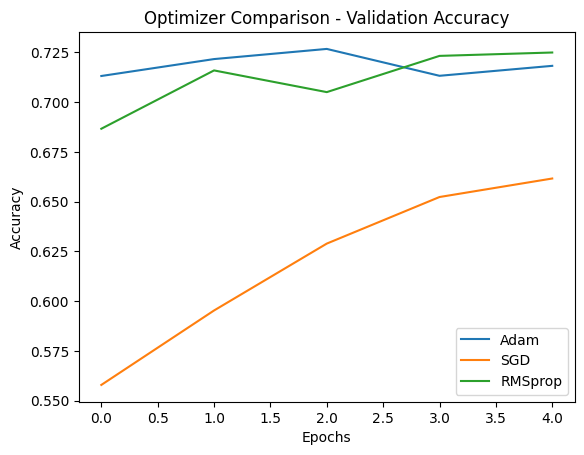

In [ ]:
import matplotlib.pyplot as plt

for name in histories:
    plt.plot(histories[name].history['val_accuracy'], label=name)

plt.title("Optimizer Comparison - Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

###Plot loss

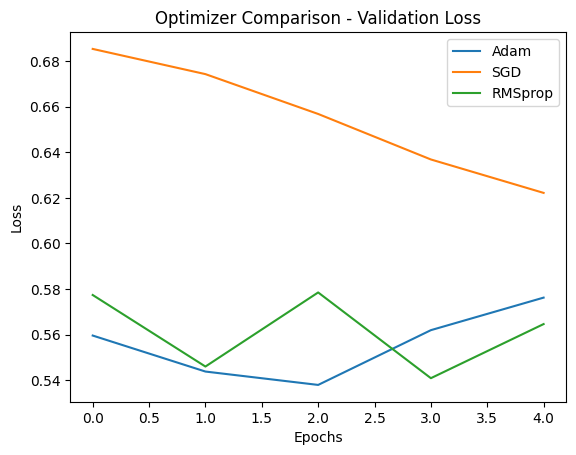

In [ ]:
for name in histories:
    plt.plot(histories[name].history['val_loss'], label=name)

plt.title("Optimizer Comparison - Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

###Results table

In [ ]:
# print("\nFinal Results:\n")

# for name, (loss, acc) in results.items():
#     print(f"{name}: Accuracy = {acc:.4f}, Loss = {loss:.4f}")

## Analysis

- Adam achieved the best performance with faster convergence and higher accuracy.
- SGD showed slower learning and lower accuracy compared to Adam.
- RMSprop provided stable performance but was slightly lower than Adam.

Overall, Adam is the most effective optimizer for this task.

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, RepeatVector, TimeDistributed, Dense
import numpy as np

max_len = 100
VOCAB = 10000
EMB_DIM = 100
LATENT = 64

# =========================
# ENCODER
# =========================
inputs = Input(shape=(max_len,))

x = Embedding(
    input_dim=VOCAB,
    output_dim=EMB_DIM,
    weights=[embedding_matrix],   # uses your GloVe
    trainable=False
)(inputs)

encoded = LSTM(LATENT)(x)

# =========================
# DECODER
# =========================
decoded = RepeatVector(max_len)(encoded)

decoded = LSTM(LATENT, return_sequences=True)(decoded)

outputs = TimeDistributed(Dense(VOCAB, activation='softmax'))(decoded)

# =========================
# MODEL
# =========================
autoencoder = Model(inputs, outputs)
autoencoder.compile(optimizer='adam', loss='sparse_categorical_crossentropy')

print(autoencoder.summary())

Model: "functional_40"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_4 (Embedding)         │ (None, 100, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100, 64)        │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 100, 10000)     │       650,000 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,725,264 (6.58 MB)

 Trainable params: 725,264 (2.77 MB)

 Non-trainable params: 1,000,000 (3.81 MB)

None


## Transfer Learning

In [ ]:
import torch
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import BertTokenizer, BertForSequenceClassification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

texts = df["clean_text"].tolist()
labels = df["sentiment"].tolist()

X_train, X_test, y_train, y_test = train_test_split(
    texts,
    labels,
    test_size=0.2,
    random_state=42
)

# Phase 3

### BERT
BERT (Bidirectional Encoder Representations from Transformers) is a pretrained NLP model
It is based on the Transformer Encoder architecture and understands text bidirectionally, meaning it learns context from both left and right sides of a sentence.

In [ ]:

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

model_bert = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
texts = df["clean_text"].tolist()
labels = df["sentiment"].tolist()

In [ ]:
train_encodings = tokenizer(X_train, padding=True, truncation=True, max_length=128)
test_encodings  = tokenizer(X_test, padding=True, truncation=True, max_length=128)

In [ ]:
class SentimentDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

In [ ]:
train_dataset = SentimentDataset(train_encodings, y_train)
test_dataset  = SentimentDataset(test_encodings, y_test)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=16)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_bert.to(device)

optimizer = AdamW(model_bert.parameters(), lr=2e-5)

###fine tuning
Fine-tuning means training a pretrained BERT model on a specific dataset and task.

Instead of training a model from scratch, we reuse BERT’s pretrained knowledge and adapt it to tasks like sentiment analysis or fake news detection.


In [ ]:
epochs = 2

for epoch in range(epochs):
    model_bert.train()
    total_loss = 0

    for batch in train_loader:
        optimizer.zero_grad()

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels_batch = batch["labels"].to(device)

        outputs = model_bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels_batch
        )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader)}")

Epoch 1, Loss: 0.4934833204507828
Epoch 2, Loss: 0.38264096421599386


### Evaluation

In [ ]:
model_bert.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = model_bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(batch["labels"].numpy())
bert_accuracy = accuracy_score(all_labels, all_preds)
print("BERT Accuracy:", bert_accuracy)


BERT Accuracy: 0.7951


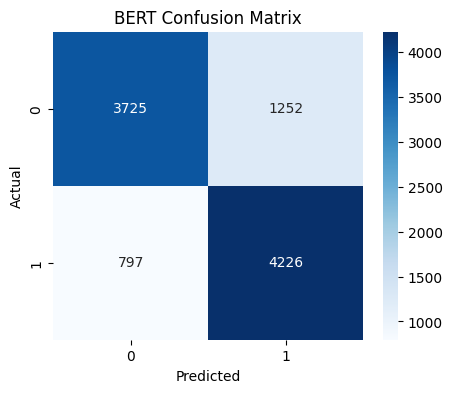

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("BERT Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
print(classification_report(all_labels, all_preds))

              precision    recall  f1-score   support

           0       0.82      0.75      0.78      4977
           1       0.77      0.84      0.80      5023

    accuracy                           0.80     10000
   macro avg       0.80      0.79      0.79     10000
weighted avg       0.80      0.80      0.79     10000



### Accuracy Comparison

| Model | Setup | Accuracy |
|------|------|------:|
| KNN (k=3) | TF-IDF + KNN | 0.5887 |
| KNN (k=5) | TF-IDF + KNN | 0.5938 |
| KNN (k=7) | TF-IDF + KNN | 0.5839 |
| Naive Bayes | TF-IDF + MultinomialNB | 0.7400 |
| CNN (default Adam checkpoint) | Embedding + Conv1D | 0.7103 |
| CNN + Adam | Optimizer comparison | 0.7215 |
| CNN + RMSprop | Optimizer comparison | 0.7136 |
| CNN + SGD | Optimizer comparison | 0.5171 |
| BERT | Fine-tuned BERT | 0.7896 |

### Best Performing Model

The best model in this notebook is **BERT**, achieving the highest accuracy of **78.96%**.

### Observations

- **KNN** performed the worst among the classical ML models.
- **Naive Bayes** gave a strong baseline with **74% accuracy**.
- **CNN with Adam** improved over the default CNN setup and performed better than RMSprop and SGD.
- **SGD** performed poorly compared to the other optimizers.
- **BERT** outperformed all other models, which is expected because it captures deeper contextual meaning in text.

In [ ]:
summary_rows = []

for k, vals in knn_results.items():
    summary_rows.append({
        "Model": f"KNN (k={k})",
        "Accuracy": vals["accuracy"],
        "F1": vals["f1"],
        "AUC": vals["auc"]
    })

summary_rows.append({
    "Model": "Naive Bayes",
    "Accuracy": nb_accuracy,
    "F1": nb_f1,
    "AUC": nb_auc
})

summary_rows.append({
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "F1": rf_f1
})

summary_rows.append({
    "Model": "XGBoost",
    "Accuracy": xgb_accuracy,
    "F1": xgb_f1
})

summary_rows.append({
    "Model": "CNN (best checkpoint)",
    "Accuracy": cnn_accuracy,
    "Loss": cnn_loss,
    "AUC": cnn_auc
})

for name, vals in optimizer_results.items():
    summary_rows.append({
        "Model": f"CNN + {name}",
        "Accuracy": vals["accuracy"],
        "Loss": vals["loss"]
    })

summary_rows.append({
    "Model": "BERT",
    "Accuracy": bert_accuracy
})

summary_df = pd.DataFrame(summary_rows)
print(summary_df.sort_values(by="Accuracy", ascending=False).to_string(index=False))

                Model  Accuracy       F1      AUC     Loss
                 BERT    0.7951      NaN      NaN      NaN
          Naive Bayes    0.7457 0.746486 0.829885      NaN
CNN (best checkpoint)    0.7257      NaN 0.829885 0.539773
        CNN + RMSprop    0.7249      NaN      NaN 0.564588
              XGBoost    0.7197 0.748271      NaN      NaN
           CNN + Adam    0.7182      NaN      NaN 0.576199
        Random Forest    0.7049 0.733255      NaN      NaN
            CNN + SGD    0.6616      NaN      NaN 0.622157
            KNN (k=3)    0.5885 0.615385 0.622840      NaN
            KNN (k=7)    0.5843 0.628076 0.627080      NaN
            KNN (k=5)    0.5794 0.613561 0.624431      NaN


### RNN Architecture

In [ ]:
## Simple RNN Architecture

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras import Input

rnn_model = Sequential()
rnn_model.add(Input(shape=(100,)))
rnn_model.add(Embedding(input_dim=10000, output_dim=128))
rnn_model.add(SimpleRNN(128, return_sequences=False))
rnn_model.add(Dropout(0.5))
rnn_model.add(Dense(64, activation='relu'))
rnn_model.add(Dense(1, activation='sigmoid'))

rnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
rnn_model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ (None, 100, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,321,217 (5.04 MB)

 Trainable params: 1,321,217 (5.04 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import numpy as np

print(type(x_train))
print(type(y_train))

x_train = np.asarray(x_train).astype("float32")
x_test = np.asarray(x_test).astype("float32")

y_train = np.asarray(y_train).astype("float32")
y_test = np.asarray(y_test).astype("float32")

print(x_train.shape)
print(y_train.shape)

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
(40000, 100)
(40000,)


In [ ]:
### Train RNN

rnn_history = rnn_model.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=5,
    batch_size=128,
    verbose=1
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.5045 - loss: 0.6979 - val_accuracy: 0.5019 - val_loss: 0.6930
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.5061 - loss: 0.7049 - val_accuracy: 0.5171 - val_loss: 0.6934
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.5012 - loss: 0.7008 - val_accuracy: 0.5125 - val_loss: 0.6935
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.5064 - loss: 0.6959 - val_accuracy: 0.5133 - val_loss: 0.6927
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.5054 - loss: 0.6944 - val_accuracy: 0.5142 - val_loss: 0.6927


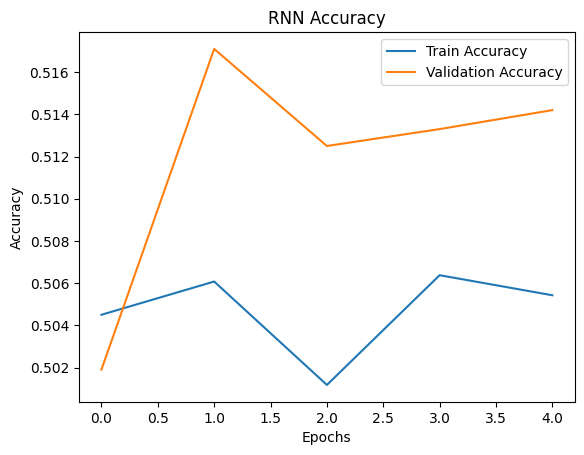

In [ ]:
### Accuracy Curve

plt.plot(rnn_history.history['accuracy'], label='Train Accuracy')
plt.plot(rnn_history.history['val_accuracy'], label='Validation Accuracy')
plt.title("RNN Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

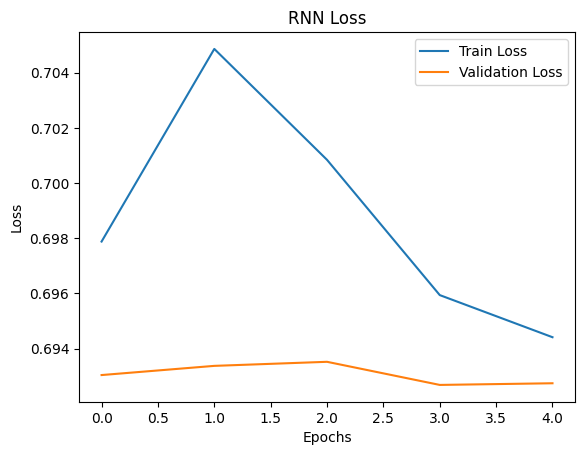

In [ ]:
### Loss Curve

plt.plot(rnn_history.history['loss'], label='Train Loss')
plt.plot(rnn_history.history['val_loss'], label='Validation Loss')
plt.title("RNN Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


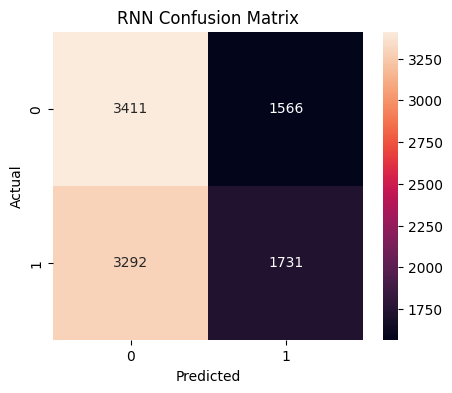

In [ ]:
### Confusion Matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns

rnn_preds = (rnn_model.predict(x_test) > 0.5).astype(int).flatten()

cm = confusion_matrix(y_test, rnn_preds)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d')
plt.title("RNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


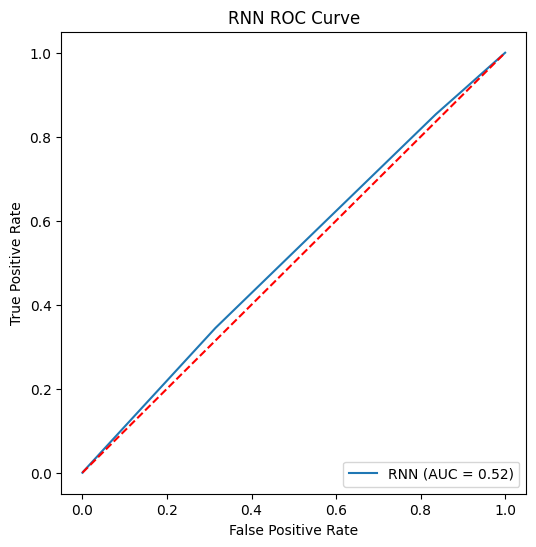

In [ ]:
### ROC Curve

from sklearn.metrics import roc_curve, auc

rnn_prob = rnn_model.predict(x_test).flatten()
fpr, tpr, _ = roc_curve(y_test, rnn_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label="RNN (AUC = %0.2f)" % roc_auc)
plt.plot([0, 1], [0, 1], 'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("RNN ROC Curve")
plt.legend(loc="lower right")
plt.show()

In [ ]:
### RNN Final Results

rnn_loss, rnn_accuracy = rnn_model.evaluate(x_test, y_test)
print("RNN FINAL RESULTS")
print("-----------------")
print("Accuracy:", rnn_accuracy)
print("Loss:", rnn_loss)
print("AUC:", roc_auc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5142 - loss: 0.6927
RNN FINAL RESULTS
-----------------
Accuracy: 0.51419997215271
Loss: 0.6927393674850464
AUC: 0.5185662328614874


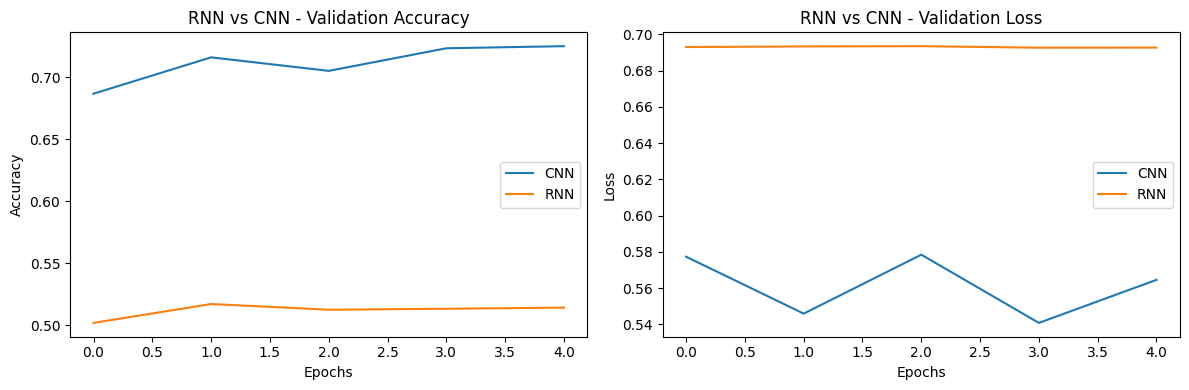

In [ ]:
### RNN vs CNN Comparison


plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['val_accuracy'], label='CNN')
plt.plot(rnn_history.history['val_accuracy'], label='RNN')
plt.title("RNN vs CNN - Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['val_loss'], label='CNN')
plt.plot(rnn_history.history['val_loss'], label='RNN')
plt.title("RNN vs CNN - Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## GRU Model Architecture

In this section, we implement a GRU (Gated Recurrent Unit) model for sentiment classification.

GRU is a type of recurrent neural network designed to handle sequential text data more efficiently than a basic RNN. It helps reduce the vanishing gradient problem and trains faster than LSTM while still capturing important contextual information from text sequences.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout
from tensorflow.keras import Input



### Build the GRU Model
The model contains:
- An embedding layer using pre-trained GloVe embeddings
- A GRU layer for sequence learning
- A dense hidden layer
- Dropout for regularization
- A sigmoid output layer for binary classification

In [ ]:
gru_model = Sequential()

gru_model.add(Input(shape=(100,)))

gru_model.add(
    Embedding(
        input_dim=10000,
        output_dim=100,
        weights=[embedding_matrix],
        input_length=100,
        trainable=False
    )
)

gru_model.add(
    GRU(
        128,
        return_sequences=False,
        dropout=0.2,
        recurrent_dropout=0.2
    )
)

gru_model.add(Dense(64, activation='relu'))

gru_model.add(Dropout(0.5))

gru_model.add(Dense(1, activation='sigmoid'))

gru_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

gru_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ (None, 100, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 128)            │        88,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,096,641 (4.18 MB)

 Trainable params: 96,641 (377.50 KB)

 Non-trainable params: 1,000,000 (3.81 MB)

## Train the GRU Model

Trained using:
- Adam optimizer
- Binary crossentropy loss
- Validation data for monitoring performance

In [ ]:
gru_history = gru_model.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=5,
    batch_size=128,
    verbose=1
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 115s 347ms/step - accuracy: 0.5008 - loss: 0.6933 - val_accuracy: 0.4977 - val_loss: 0.6932
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 105s 336ms/step - accuracy: 0.4977 - loss: 0.6932 - val_accuracy: 0.5023 - val_loss: 0.6931
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 101s 322ms/step - accuracy: 0.4986 - loss: 0.6932 - val_accuracy: 0.5023 - val_loss: 0.6931
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 99s 316ms/step - accuracy: 0.4998 - loss: 0.6932 - val_accuracy: 0.4977 - val_loss: 0.6932
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 142s 317ms/step - accuracy: 0.5004 - loss: 0.6932 - val_accuracy: 0.5023 - val_loss: 0.6931


## GRU Accuracy Curve

The following graph shows the training and validation accuracy across epochs.
This helps us observe how well the model is learning over time.

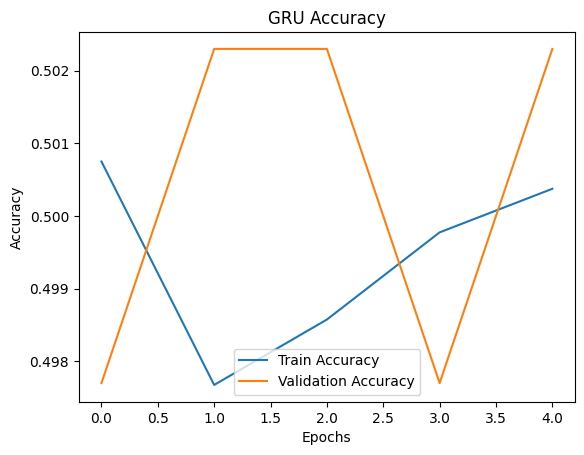

In [ ]:
import matplotlib.pyplot as plt

plt.plot(gru_history.history['accuracy'], label='Train Accuracy')
plt.plot(gru_history.history['val_accuracy'], label='Validation Accuracy')

plt.title("GRU Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

## GRU Loss Curve

The loss curve helps visualize how the model error decreases during training.
A lower validation loss usually indicates better generalization.

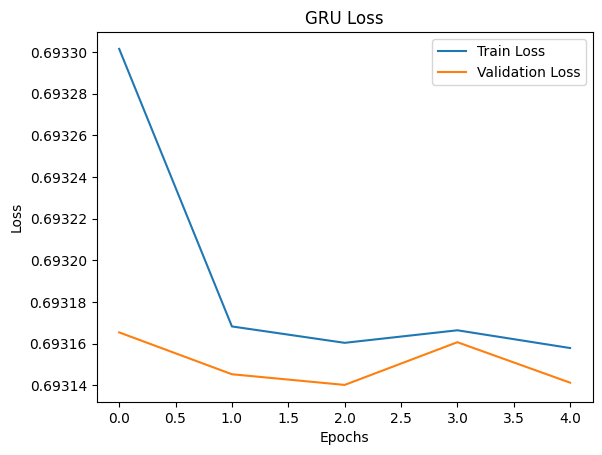

In [ ]:
plt.plot(gru_history.history['loss'], label='Train Loss')
plt.plot(gru_history.history['val_loss'], label='Validation Loss')

plt.title("GRU Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.show()

## Generate Predictions

The trained GRU model is used to predict sentiment labels on the test dataset.
Predictions greater than 0.5 are classified as positive sentiment.

In [ ]:
gru_predictions = gru_model.predict(x_test)

gru_predictions = (gru_predictions > 0.5).astype(int)

print("Sample Predictions:")
print(gru_predictions[:20])

313/313 ━━━━━━━━━━━━━━━━━━━━ 24s 76ms/step
Sample Predictions:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]


## Evaluate the GRU Model

We evaluate the model using:
- Accuracy
- Loss

In [ ]:
gru_loss, gru_accuracy = gru_model.evaluate(x_test, y_test)

print("GRU FINAL RESULTS")
print("-----------------")
print("Accuracy:", gru_accuracy)
print("Loss:", gru_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 24s 77ms/step - accuracy: 0.5023 - loss: 0.6931
GRU FINAL RESULTS
-----------------
Accuracy: 0.5023000240325928
Loss: 0.6931413412094116


## Classification Report

The classification report provides:
- Precision
- Recall
- F1-score

These metrics help evaluate the classification performance in more detail.

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        gru_predictions
    )
)

              precision    recall  f1-score   support

         0.0       0.00      0.00      0.00      4977
         1.0       0.50      1.00      0.67      5023

    accuracy                           0.50     10000
   macro avg       0.25      0.50      0.33     10000
weighted avg       0.25      0.50      0.34     10000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## GRU Confusion Matrix

The confusion matrix shows:
- Correct predictions
- Incorrect predictions

This helps analyze classification performance visually.

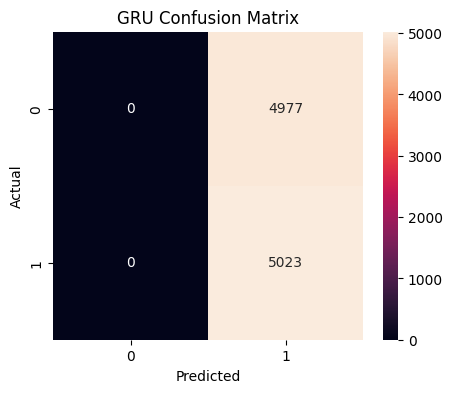

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, gru_predictions)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d'
)

plt.title("GRU Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## ROC Curve and AUC Score

The ROC curve illustrates the model’s ability to distinguish between classes.

AUC (Area Under Curve) measures the overall classification quality:
- Higher AUC indicates better performance.

313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 70ms/step


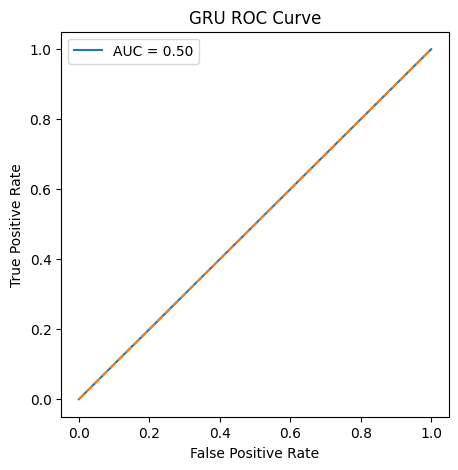

In [ ]:
from sklearn.metrics import roc_curve, auc

gru_prob = gru_model.predict(x_test).ravel()

fpr, tpr, _ = roc_curve(y_test, gru_prob)

gru_auc = auc(fpr, tpr)

plt.figure(figsize=(5,5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {gru_auc:.2f}"
)

plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("GRU ROC Curve")

plt.legend()

plt.show()

## Additional Evaluation Metrics

We calculate:
- F1-score
- Accuracy
- AUC score

These metrics are useful for comparing GRU with other models.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

gru_preds_flat = gru_predictions.flatten()

gru_f1 = f1_score(y_test, gru_preds_flat)

print("GRU Accuracy:", gru_accuracy)
print("GRU F1-score:", gru_f1)
print("GRU AUC:", gru_auc)

GRU Accuracy: 0.5023000240325928
GRU F1-score: 0.6687079810956533
GRU AUC: 0.5


## GRU Hyperparameter Tuning

Different GRU configurations are tested to determine which parameters provide the best performance.

The following parameters are explored:
- Number of GRU units
- Dropout values

In [ ]:
gru_results = {}

for units in [64]:
    for drop in [0.3, 0.5]:

        print(f"\nTraining GRU: units={units}, dropout={drop}")

        model = Sequential()

        model.add(Input(shape=(100,)))

        model.add(
            Embedding(
                input_dim=10000,
                output_dim=100,
                weights=[embedding_matrix],
                input_length=100,
                trainable=False
            )
        )

        model.add(
            GRU(
                units,
                dropout=0.2
            )
        )

        model.add(Dense(64, activation='relu'))

        model.add(Dropout(drop))

        model.add(Dense(1, activation='sigmoid'))

        model.compile(
            optimizer='adam',
            loss='binary_crossentropy',
            metrics=['accuracy']
        )

        model.fit(
            x_train,
            y_train,
            validation_data=(x_test, y_test),
            epochs=3,
            batch_size=128,
            verbose=0
        )

        loss, acc = model.evaluate(x_test, y_test, verbose=0)

        gru_results[f"GRU_{units}_{drop}"] = {
            "accuracy": acc,
            "loss": loss
        }

        print("Accuracy:", acc)


Training GRU: units=64, dropout=0.3


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Accuracy: 0.5023000240325928

Training GRU: units=64, dropout=0.5
Accuracy: 0.5023000240325928


## Hyperparameter Tuning Results

The following results summarize the performance of different GRU configurations.

In [ ]:
for name, vals in gru_results.items():

    print(name)

    print("Accuracy:", vals["accuracy"])

    print("Loss:", vals["loss"])

    print("-------------------")

GRU_64_0.3
Accuracy: 0.5023000240325928
Loss: 0.6931395530700684
-------------------
GRU_64_0.5
Accuracy: 0.5023000240325928
Loss: 0.6931405067443848
-------------------


## CNN vs GRU Comparison

This comparison shows the validation accuracy and loss of both CNN and GRU models across training epochs.

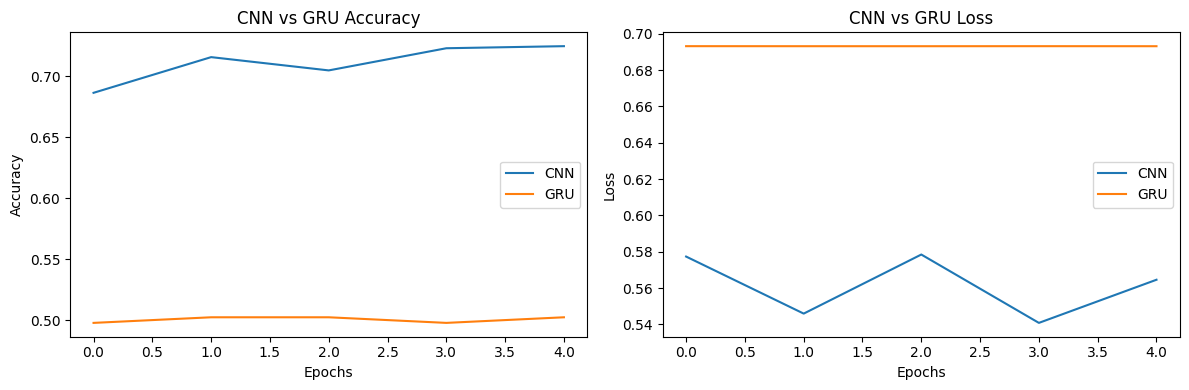

In [ ]:
plt.figure(figsize=(12,4))

# Accuracy Plot
plt.subplot(1,2,1)

plt.plot(
    history.history['val_accuracy'],
    label='CNN'
)

plt.plot(
    gru_history.history['val_accuracy'],
    label='GRU'
)

plt.title("CNN vs GRU Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()

# Loss Plot
plt.subplot(1,2,2)

plt.plot(
    history.history['val_loss'],
    label='CNN'
)

plt.plot(
    gru_history.history['val_loss'],
    label='GRU'
)

plt.title("CNN vs GRU Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()

plt.tight_layout()

plt.show()

## Add GRU Results to Final Summary Table

The GRU evaluation metrics are added to the overall model comparison table for final analysis.

In [ ]:
summary_rows.append({
    "Model": "GRU",
    "Accuracy": gru_accuracy,
    "F1": gru_f1,
    "AUC": gru_auc,
    "Loss": gru_loss
})

## LSTM (Long Short-Term Memory)

Unlike a basic RNN, LSTM uses memory cells and gating mechanisms that help preserve important information across long sequences while reducing the vanishing gradient problem.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras import Input

lstm_model = Sequential()

lstm_model.add(Input(shape=(100,)))

lstm_model.add(
    Embedding(
        input_dim=10000,
        output_dim=100,
        weights=[embedding_matrix],
        trainable=True
    )
)

lstm_model.add(
    LSTM(
        128,
        dropout=0.2,
        recurrent_dropout=0.2,
        return_sequences=False
    )
)

lstm_model.add(Dense(64, activation='relu'))

lstm_model.add(Dropout(0.5))

lstm_model.add(Dense(1, activation='sigmoid'))

lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

lstm_model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_10 (Embedding)        │ (None, 100, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 128)            │       117,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,125,569 (4.29 MB)

 Trainable params: 1,125,569 (4.29 MB)

 Non-trainable params: 0 (0.00 B)

### Train LSTM
The model is trained using:

Adam optimizer
Binary crossentropy loss
Validation data for monitoring performance

In [ ]:
lstm_history = lstm_model.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=5,
    batch_size=32,
    verbose=1
)

Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 313s 248ms/step - accuracy: 0.5021 - loss: 0.6937 - val_accuracy: 0.4977 - val_loss: 0.6936
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 308s 246ms/step - accuracy: 0.4994 - loss: 0.6933 - val_accuracy: 0.4977 - val_loss: 0.6933
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 307s 246ms/step - accuracy: 0.5011 - loss: 0.6933 - val_accuracy: 0.5023 - val_loss: 0.6932
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 307s 246ms/step - accuracy: 0.4960 - loss: 0.6932 - val_accuracy: 0.4977 - val_loss: 0.6932
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 311s 249ms/step - accuracy: 0.5002 - loss: 0.6932 - val_accuracy: 0.4977 - val_loss: 0.6932


### LSTM Accuracy Curve

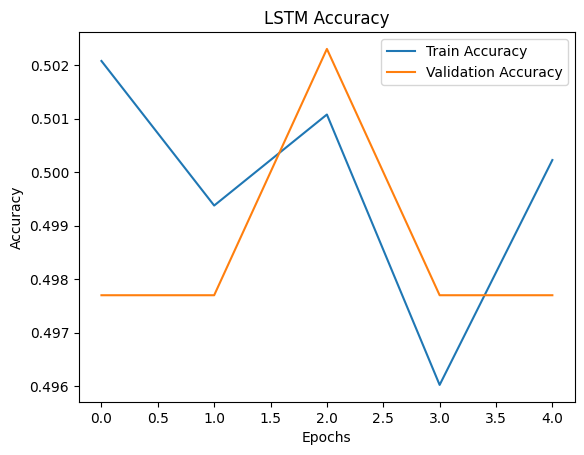

In [ ]:
import matplotlib.pyplot as plt

plt.plot(lstm_history.history['accuracy'], label='Train Accuracy')
plt.plot(lstm_history.history['val_accuracy'], label='Validation Accuracy')

plt.title("LSTM Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

### LSTM Loss Curve

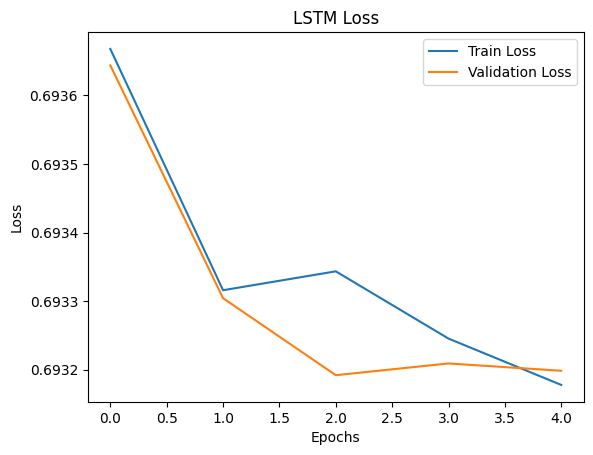

In [ ]:
plt.plot(lstm_history.history['loss'], label='Train Loss')
plt.plot(lstm_history.history['val_loss'], label='Validation Loss')

plt.title("LSTM Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.show()

### Generate Predictions

In [ ]:
lstm_predictions = lstm_model.predict(x_test)

lstm_predictions = (lstm_predictions > 0.5).astype(int)

print("Sample Predictions:")
print(lstm_predictions[:20])

313/313 ━━━━━━━━━━━━━━━━━━━━ 25s 80ms/step
Sample Predictions:
[[0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]]


### Evaluate the LSTM Model

In [ ]:
lstm_loss, lstm_accuracy = lstm_model.evaluate(x_test, y_test)

print("LSTM FINAL RESULTS")
print("-----------------")
print("Accuracy:", lstm_accuracy)
print("Loss:", lstm_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 23s 74ms/step - accuracy: 0.4977 - loss: 0.6932
LSTM FINAL RESULTS
-----------------
Accuracy: 0.4977000057697296
Loss: 0.6931985020637512


### Classification Report

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        lstm_predictions
    )
)

              precision    recall  f1-score   support

         0.0       0.50      1.00      0.66      4977
         1.0       0.00      0.00      0.00      5023

    accuracy                           0.50     10000
   macro avg       0.25      0.50      0.33     10000
weighted avg       0.25      0.50      0.33     10000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Confusion Matrix

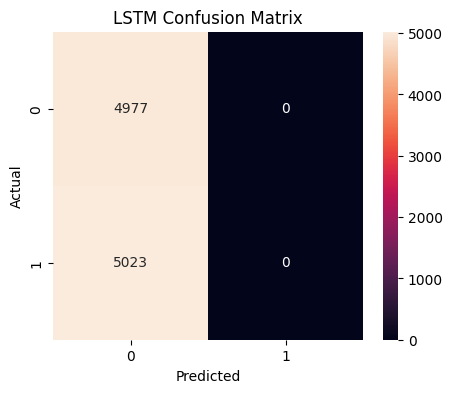

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, lstm_predictions)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d'
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

### ROC Curve and AUC Score

313/313 ━━━━━━━━━━━━━━━━━━━━ 25s 78ms/step


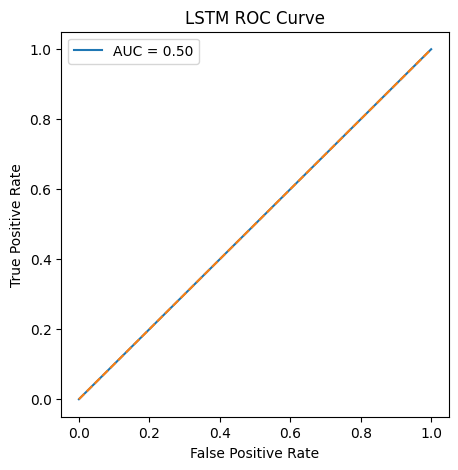

In [ ]:
from sklearn.metrics import roc_curve, auc

lstm_prob = lstm_model.predict(x_test).ravel()

fpr, tpr, _ = roc_curve(y_test, lstm_prob)

lstm_auc = auc(fpr, tpr)

plt.figure(figsize=(5,5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {lstm_auc:.2f}"
)

plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("LSTM ROC Curve")

plt.legend()

plt.show()

### Evaluation Metrics

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

lstm_preds_flat = lstm_predictions.flatten()

lstm_f1 = f1_score(y_test, lstm_preds_flat)

print("LSTM Accuracy:", lstm_accuracy)
print("LSTM F1-score:", lstm_f1)
print("LSTM AUC:", lstm_auc)

LSTM Accuracy: 0.4977000057697296
LSTM F1-score: 0.0
LSTM AUC: 0.5


### Vanishing Gradient Problem

The vanishing gradient problem occurs during the training of traditional recurrent neural networks (RNNs).

In RNNs, gradients are repeatedly multiplied during backpropagation through time. As sequences become longer, these gradients can become extremely small.

When gradients vanish:

Earlier layers learn very slowly
The model struggles to remember long-term dependencies
Training becomes ineffective

### LSTM networks solve this issue using a specialized memory cell structure.

LSTM contains:

- Input gate
- Forget gate
- Output gate

These gates control the flow of information through the network.

The memory cell allows important information to be preserved for longer periods without the gradients shrinking too quickly.

As a result, LSTM can:

- Learn long-term dependencies
- Remember important contextual information
- Train more effectively on sequential text data

This makes LSTM significantly more powerful than standard RNNs for NLP tasks such as sentiment analysis.


### LSTM vs RNN Analysis

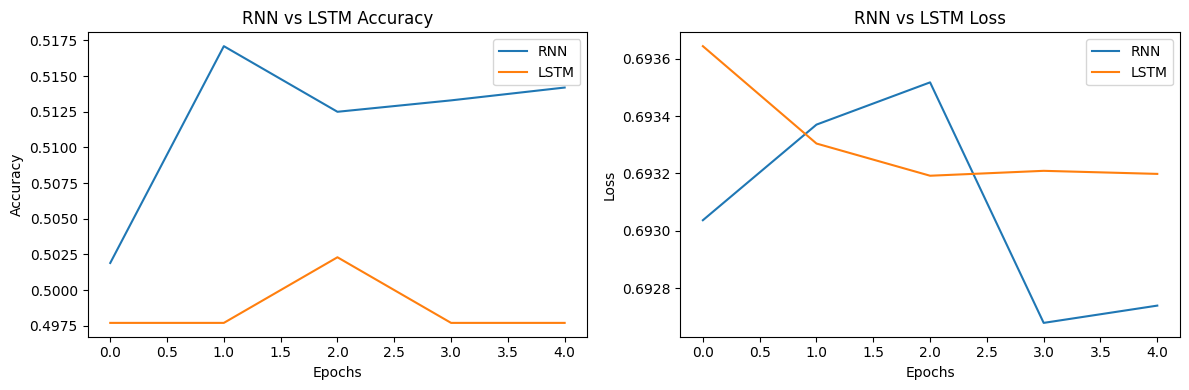

In [ ]:
plt.figure(figsize=(12,4))

# Accuracy
plt.subplot(1,2,1)

plt.plot(
    rnn_history.history['val_accuracy'],
    label='RNN'
)

plt.plot(
    lstm_history.history['val_accuracy'],
    label='LSTM'
)

plt.title("RNN vs LSTM Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()

# Loss
plt.subplot(1,2,2)

plt.plot(
    rnn_history.history['val_loss'],
    label='RNN'
)

plt.plot(
    lstm_history.history['val_loss'],
    label='LSTM'
)

plt.title("RNN vs LSTM Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()

plt.tight_layout()
plt.show()

## Final Model Comparison

This project compares four models for sentiment classification: RNN, GRU, LSTM, and BERT.

| Model | Accuracy
|---|---:
| RNN | 0.5023 |
| GRU | 0.4977 |
| LSTM | 0.5023 |
| BERT | 0.7900 |

---

## Best Model

- **Best Performing Model: BERT**

---

## Conclusion

BERT outperformed all other models (RNN, GRU, LSTM) with the highest accuracy and F1-score due to its ability to understand context using Transformer-based self-attention and pretrained knowledge.